In [2]:
import numpy as np
import pandas as pd
SEED = 42

train = pd.read_csv('data/train.csv', parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'])
test = pd.read_csv('data/test.csv', parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'])
events = pd.read_csv('data/events.csv.gz', parse_dates=['event_ts'])

print(train.shape, test.shape, events.shape)
print('доля ботов в train:', train.target.mean().round(4))
train.head()

(11091, 5) (4909, 4) (328905, 14)
доля ботов в train: 0.0811


,cookie_id,cookie_created_at,window_start_ts,window_end_ts,target
0,ck_54a059eb7d3ea68b,2025-11-21 09:30:41,2026-04-06,2026-04-07,0
1,ck_7e4de46eeab82974,2025-09-23 10:10:24,2026-04-06,2026-04-07,0
2,ck_9320229ef6304522,2026-03-04 00:08:02,2026-04-06,2026-04-07,0
3,ck_30ccd25bc1714ed9,2026-04-05 10:52:40,2026-04-06,2026-04-07,0
4,ck_a77c5f05948cdeef,2026-01-01 03:54:35,2026-04-06,2026-04-07,0


In [3]:
print(events.event_name.value_counts(), '\n')
print(events.platform.value_counts(), '\n')
print('пропуски по колонкам:')
print(events.isna().mean().round(3))

event_name
item_view               120817
search_results_view     100402
photo_swipe              36517
favorite_add             19049
seller_page_view         17403
contact_phone_show       11316
captcha_shown             7928
login                     6267
contact_chat_open         6125
contact_message_sent      3081
Name: count, dtype: int64 

platform
desktop    46866
WEB        46476
Web        46365
web        45951
ANDROID    42462
Android    42254
android    42159
iphone      4103
IOS         4100
iOS         4091
ios         4078
Name: count, dtype: int64 

пропуски по колонкам:
cookie_id        0.000
event_ts         0.000
eid              0.000
event_name       0.000
platform         0.000
user_agent       0.000
item_id          0.348
item_category    0.100
item_location    0.072
seller_type      0.407
search_query     0.695
search_page      0.695
pointer_x        0.670
pointer_y        0.670
dtype: float64


In [4]:
def events_in_window(events, meta):
    ev = events.merge(meta[['cookie_id', 'window_start_ts', 'window_end_ts']], on='cookie_id')
    return ev[(ev.event_ts >= ev.window_start_ts) & (ev.event_ts < ev.window_end_ts)]

ev_tr = events_in_window(events, train)
ev_te = events_in_window(events, test)
print(len(ev_tr), len(ev_te))

198436 89690


In [5]:
ev_tr.head()

,cookie_id,event_ts,eid,event_name,platform,user_agent,item_id,item_category,item_location,seller_type,search_query,search_page,pointer_x,pointer_y,window_start_ts,window_end_ts
0,ck_d274382b19488771,2026-04-13 12:02:56,200,item_view,WEB,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,1048743.0,kvartiry_prodazha,kirov,private,NaN,NaN,675.0,276.0,2026-04-13,2026-04-14
1,ck_fbbed2ff14944ce9,2026-04-08 06:12:14,100,search_results_view,web,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,NaN,bytovaya_tehnika,novosibirsk,NaN,пылесос dyson,2.0,NaN,NaN,2026-04-08,2026-04-09
2,ck_56cc15c7c634cb9f,2026-04-12 17:16:05,100,search_results_view,WEB,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,NaN,odezhda,sankt-peterburg,NaN,костюм мужской,2.0,NaN,NaN,2026-04-12,2026-04-13
4,ck_f80d85f038cdacee,2026-04-11 16:08:12,200,item_view,desktop,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,1000845.0,bytovaya_tehnika,sankt-peterburg,private,NaN,NaN,NaN,NaN,2026-04-11,2026-04-12
5,ck_e4f046f721d10f81,2026-04-10 16:50:05,200,item_view,IOS,Mozilla/5.0 (iPhone; CPU iPhone OS 15_2 like M...,1055188.0,telefony,ekaterinburg,pro,NaN,NaN,NaN,NaN,2026-04-10,2026-04-11


Подход к решению и гипотезы.
1) Стоит рассмотреть platform, user_agent, item_category на типичность для классов. 
2) gap между соседними событиями у ботов, возможно, сильно ниже, чем у людей
3) pointer у ботов ,возможно, более статичный, чем у людей. Стоит посмотреть отклонения

Ну и цель собрать фичи. Протестировать на rf, catboost...

In [6]:
ev = ev_tr.sort_values(["cookie_id", "event_ts"]).copy()
ev = ev.merge(train[["cookie_id", "target"]], on="cookie_id")
ev["gap"] = ev.groupby("cookie_id")["event_ts"].diff().dt.total_seconds()
ev["fast_gap"] = (ev["gap"] <= 2).where(ev["gap"].notna())
ev["gap_30"] = (ev["gap"] <= 30).where(ev["gap"].notna())
ev["gap_60"] = (ev["gap"] <= 60).where(ev["gap"].notna())
ev["gap_90"] = (ev["gap"] <= 90).where(ev["gap"].notna())
ev["gap_10"] = (ev["gap"] <= 10).where(ev["gap"].notna())
ev["gap_5"] = (ev["gap"] <= 5).where(ev["gap"].notna())

ev["is_web"] = ev["platform"].str.lower() == "web"

ev.head(5)

,cookie_id,event_ts,eid,event_name,platform,user_agent,item_id,item_category,item_location,seller_type,...,window_end_ts,target,gap,fast_gap,gap_30,gap_60,gap_90,gap_10,gap_5,is_web
0,ck_000c95f1408dcb00,2026-04-19 14:49:54,100,search_results_view,Web,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,NaN,hobbi,NaN,NaN,...,2026-04-20,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
1,ck_000c95f1408dcb00,2026-04-19 14:50:17,210,photo_swipe,WEB,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,1021247.0,mebel,samara,private,...,2026-04-20,0,23.0,False,True,True,True,False,False,True
2,ck_000c95f1408dcb00,2026-04-19 15:50:21,200,item_view,web,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,1021247.0,mebel,samara,private,...,2026-04-20,0,3604.0,False,False,False,False,False,False,True
3,ck_000c95f1408dcb00,2026-04-19 15:50:47,200,item_view,web,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,1050338.0,mebel,volgograd,private,...,2026-04-20,0,26.0,False,True,True,True,False,False,True
4,ck_000c95f1408dcb00,2026-04-19 15:51:45,200,item_view,Web,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,1050338.0,NaN,volgograd,private,...,2026-04-20,0,58.0,False,False,True,True,False,False,True


In [7]:
print(ev.groupby("fast_gap")["target"].value_counts(normalize=True))
print(ev.groupby("gap_30")["target"].value_counts(normalize=True))
print(ev.groupby("gap_60")["target"].value_counts(normalize=True))
print(ev.groupby("gap_90")["target"].value_counts(normalize=True))
print(ev.groupby("gap_10")["target"].value_counts(normalize=True))
print(ev.groupby("gap_5")["target"].value_counts(normalize=True))

fast_gap  target
False     0         0.861954
          1         0.138046
True      0         0.894118
          1         0.105882
Name: proportion, dtype: float64
gap_30  target
False   0         0.935266
        1         0.064734
True    0         0.763574
        1         0.236426
Name: proportion, dtype: float64
gap_60  target
False   0         0.940231
        1         0.059769
True    0         0.816077
        1         0.183923
Name: proportion, dtype: float64
gap_90  target
False   0         0.932988
        1         0.067012
True    0         0.835991
        1         0.164009
Name: proportion, dtype: float64
gap_10  target
False   0         0.901229
        1         0.098771
True    0         0.687268
        1         0.312732
Name: proportion, dtype: float64
gap_5  target
False  0         0.874367
       1         0.125633
True   0         0.751366
       1         0.248634
Name: proportion, dtype: float64


In [8]:
# Смотрю статистики по pointer. Видно различие по классам.
pointer_stats = ev.groupby("cookie_id").agg(
    pointer_share=("pointer_x", lambda x: x.notna().mean()),
    pointer_count=("pointer_x", "count"),
    pointer_x_std=("pointer_x", "std"),
    pointer_y_std=("pointer_y", "std"),
    pointer_x_nunique=("pointer_x", "nunique"),
    pointer_y_nunique=("pointer_y", "nunique"),
    pointer_x_median=("pointer_x", "median"),
    pointer_y_median=("pointer_y", "median"),
    pointer_x_max=("pointer_x", "max"),
    pointer_y_max=("pointer_y", "max"),
).reset_index()

pointer_stats = pointer_stats.merge(
    train[["cookie_id", "target"]],
    on="cookie_id",
)

display(pointer_stats.groupby("target")[
    ["pointer_share", "pointer_count", "pointer_x_std", "pointer_y_std"]
].median())

display(pd.crosstab(
    ev["platform"].str.lower(),
    ev["pointer_x"].notna(),
    normalize="index",
))

,pointer_share,pointer_count,pointer_x_std,pointer_y_std
target,,,,
0,0.0,0.0,552.050024,308.072691
1,0.0,0.0,200.551441,200.969948


pointer_x,False,True
platform,,
android,1.000000,0.000000
desktop,0.398133,0.601867
ios,1.000000,0.000000
iphone,1.000000,0.000000
web,0.397726,0.602274


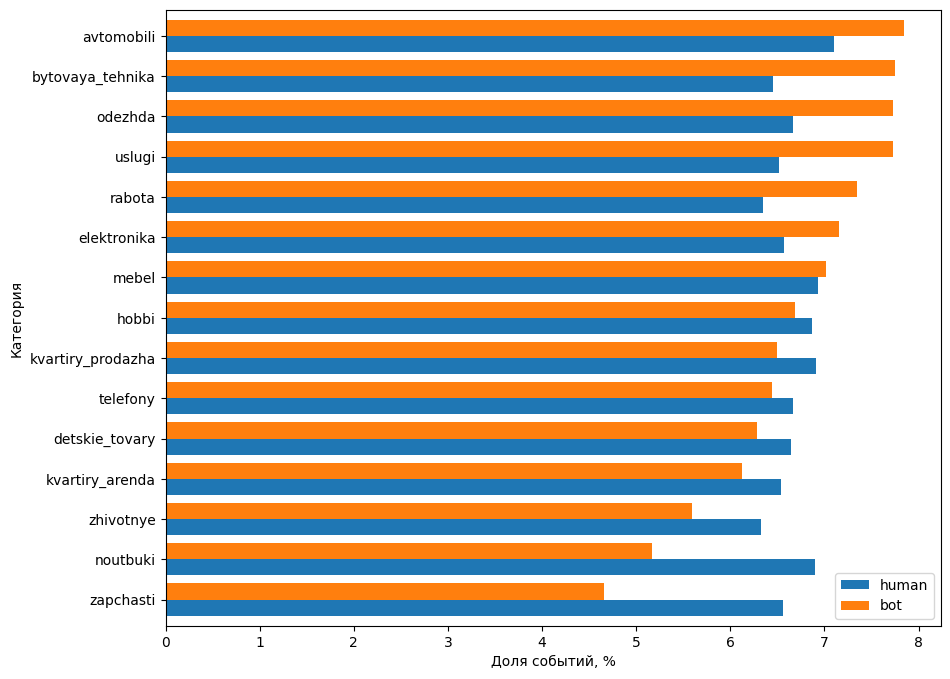

In [9]:
category_share = (
    ev.groupby("target")["item_category"]
      .value_counts(normalize=True)
      .rename("share")
      .mul(100)
      .reset_index()
)

plot_data = (
    category_share
    .pivot(index="item_category", columns="target", values="share")
    .fillna(0)
    .rename(columns={0: "human", 1: "bot"})
    .sort_values("bot")
)

ax = plot_data.plot(
    kind="barh",
    figsize=(10, 8),
    width=0.8,
)

ax.set_xlabel("Доля событий, %")
ax.set_ylabel("Категория")
ax.legend(title="")

In [11]:
# Строю отдельную df, группированную по куки. На ней будет fit модели 
cookie_stats = ev.groupby(["cookie_id", "target"]).agg(
    n_events=("event_name", "count"),
    n_items=("item_id", "nunique"),
    n_categories=("item_category", "nunique"),
    n_locations=("item_location", "nunique"),
    web_share=("is_web", "mean"),
    first_event=("event_ts", "min"),
    last_event=("event_ts", "max"),
    n_queries=("search_query", "nunique"),
    max_search_page=("search_page", "max"),
    median_gap=("gap", "median"),
    fast_gap_share=("fast_gap", "mean"),
    gap_30_share=("gap_30", "mean"),
    gap_60_share=("gap_60", "mean"),
    gap_5_share=("gap_5", "mean"),
    gap_10_share=("gap_10", "mean"),
    gap_90_share=("gap_90", "mean"),

    gap_p10=("gap", lambda x: x.quantile(0.10)),
    gap_p90=("gap", lambda x: x.quantile(0.90)),
    gap_p25=("gap", lambda x: x.quantile(0.25)),
    gap_p75=("gap", lambda x: x.quantile(0.75)),

    item_events=("item_id", "count"),

).reset_index()

cookie_stats["active_minutes"] = (
    cookie_stats["last_event"] - cookie_stats["first_event"]
).dt.total_seconds() / 60
cookie_stats = cookie_stats.drop(["first_event", "last_event"], axis=1)

cookie_stats["item_repeat_share"] = (
    (cookie_stats["item_events"] - cookie_stats["n_items"])
    / cookie_stats["item_events"].replace(0, np.nan)
)

cookie_stats["events_per_item"] = (
    cookie_stats["n_events"] / (cookie_stats["n_items"] + 1)
)


cookie_stats.head(10)

,cookie_id,target,n_events,n_items,n_categories,n_locations,web_share,n_queries,max_search_page,median_gap,...,gap_10_share,gap_90_share,gap_p10,gap_p90,gap_p25,gap_p75,item_events,active_minutes,item_repeat_share,events_per_item
0,ck_000c95f1408dcb00,0,16,9,2,8,0.937500,3,4.0,58.0,...,0.0,0.666667,18.8,7316.8,24.5,3741.50,13,501.950000,0.307692,1.600000
1,ck_000e8c52636e3bec,0,34,20,4,12,0.588235,8,12.0,23.0,...,0.212121,0.909091,2.4,64.0,12.0,49.00,24,111.350000,0.166667,1.619048
2,ck_0010e31baa4a1fb7,0,16,8,3,4,0.687500,4,1.0,334.0,...,0.066667,0.333333,24.4,6166.2,76.0,5577.00,11,706.266667,0.272727,1.777778
3,ck_0010ec3874fb5378,0,74,31,2,19,0.770270,8,6.0,32.0,...,0.232877,0.739726,5.2,2797.6,11.0,91.00,53,951.066667,0.415094,2.312500
4,ck_001722063b94cae0,0,15,8,3,9,0.000000,4,2.0,175.0,...,0.071429,0.428571,18.3,838.1,43.5,286.75,10,68.633333,0.200000,1.666667
5,ck_0029775566c17ac5,0,6,2,2,3,0.666667,2,3.0,75.0,...,0.0,0.6,39.0,4932.0,72.0,138.00,3,140.500000,0.333333,2.000000
6,ck_0030c4974c775756,0,10,5,2,5,0.000000,2,7.0,33.0,...,0.111111,0.888889,13.0,881.4,20.0,75.00,8,73.183333,0.375000,1.666667
7,ck_0032c08d8987d0ad,0,52,27,6,10,0.000000,17,14.0,27.0,...,0.176471,0.901961,8.0,89.0,12.0,52.50,33,348.550000,0.181818,1.857143
8,ck_0037dcb6ec6b40c4,0,1,1,1,1,1.000000,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1,0.000000,0.000000,0.500000
9,ck_00389b209b37394b,1,33,23,3,8,0.000000,4,4.0,77.0,...,0.15625,0.59375,1.5,3873.2,37.5,217.00,27,484.783333,0.148148,1.375000


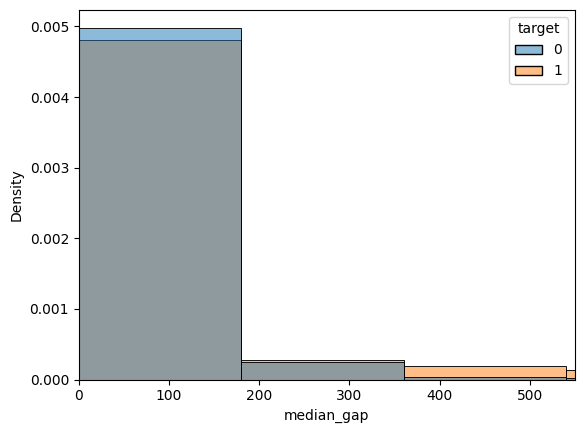

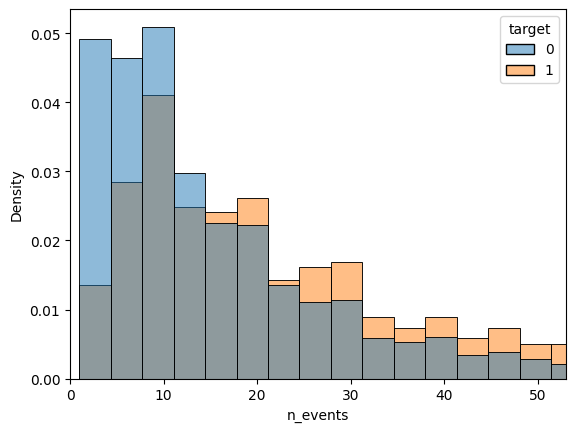

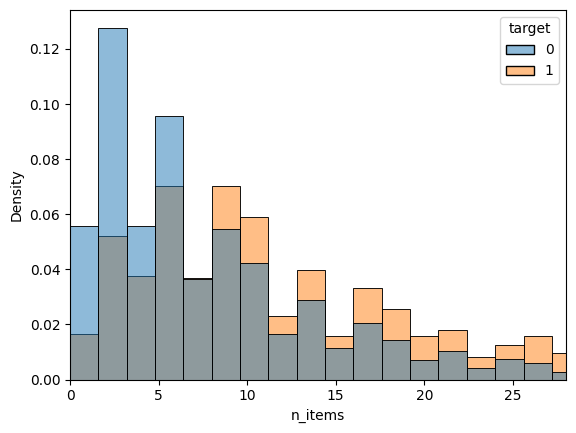

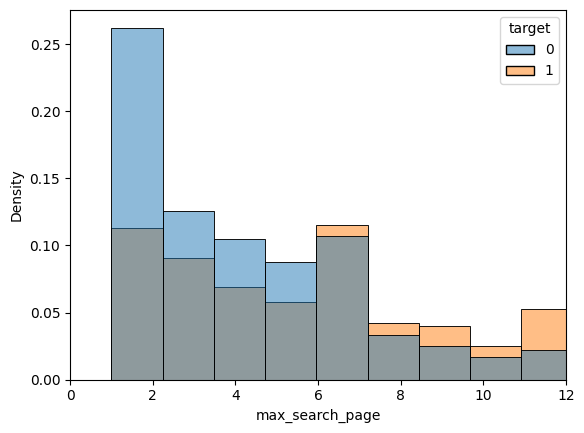

,n_events,n_items,n_categories,n_locations,web_share,median_gap,fast_gap_share,gap_p10,gap_p90,active_minutes,max_search_page,n_queries
target,,,,,,,,,,,,
0,12.0,6.0,2.0,5.0,0.500000,59.0,0.0,15.1,1557.4,138.775000,4.0,3.0
1,20.0,10.0,2.0,8.0,0.690722,25.0,0.0,8.4,124.2,151.533333,7.0,4.0


In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

# Визуально у распределений ботов более тяжелые концы. Скорее всего, потому что активность ботов выше, проводят больше действий. Фичи на кол-во действий также будут использованы в модели
# Также заметно, что gap действительно у ботов ниже

cols = ["median_gap", "n_events", "n_items", "max_search_page"]

for col in cols:
    sns.histplot(
        data=cookie_stats,
        x=col,
        hue="target",
        stat="density",
        common_norm=False,
        bins=50,
    )
    plt.xlim(0, cookie_stats[col].quantile(0.95))
    plt.show()


display(cookie_stats.groupby("target")[
    ["n_events", "n_items", "n_categories",
     "n_locations", "web_share", "median_gap", "fast_gap_share", "gap_p10", "gap_p90", "active_minutes", "max_search_page", "n_queries"]
].median())

In [13]:
event_counts = pd.crosstab(ev["cookie_id"], ev["event_name"])
event_share = event_counts.div(event_counts.sum(axis=1), axis=0)
event_share = event_share.join(train.set_index("cookie_id")["target"])

event_share.groupby("target").mean().T

target,0,1
contact_chat_open,0.016645,0.018093
contact_message_sent,0.008091,0.010416
contact_phone_show,0.030725,0.033282
favorite_add,0.068735,0.033013
item_view,0.364250,0.424916
login,0.023179,0.009808
photo_swipe,0.127041,0.078164
search_results_view,0.308472,0.331261
seller_page_view,0.052861,0.061046


In [14]:
# Считаем кол-во и доли event, platform для каждой куки. Тоже идут в модель

cookie_stats = cookie_stats.merge(
    pointer_stats.drop(columns="target"),
    on="cookie_id",
    how="left",
)

event_counts = pd.crosstab(
    ev["cookie_id"], ev["event_name"]
).add_prefix("event_count_")

event_shares = event_counts.div(
    event_counts.sum(axis=1), axis=0
).add_prefix("share_")

platform_counts = pd.crosstab(
    ev["cookie_id"], ev["platform"].str.lower()
).add_prefix("platform_count_")

platform_shares = platform_counts.div(
    platform_counts.sum(axis=1), axis=0
).add_prefix("share_")

cookie_stats = (
    cookie_stats.set_index("cookie_id")
    .join([event_counts, event_shares, platform_counts, platform_shares])
    .reset_index()
)

In [17]:
# Валидация как в quickstart для сравнения

from sklearn.ensemble import RandomForestClassifier
from metric import precision_at_recall

data = cookie_stats.merge(train[["cookie_id", "window_start_ts"]], on="cookie_id")

cols = cookie_stats.columns.drop(["cookie_id", "target"])
X = data[cols].astype(float).fillna(-1)
y = data["target"]

valid = data["window_start_ts"] >= "2026-04-17"

rf_model = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=3,
    random_state=SEED,
    n_jobs=-1
)

rf_model.fit(X.loc[~valid], y.loc[~valid])
pred = rf_model.predict_proba(X.loc[valid])[:, 1]

print("P@R0.7:", precision_at_recall(y.loc[valid], pred))
print("Доля ботов на валидации:", y.loc[valid].mean())

P@R0.7: 0.6706586826347305
Доля ботов на валидации: 0.08200922603792926


In [19]:
# Нормальная kfold валидация для временных рядов без leakage.

from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier
from metric import precision_at_recall
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

days = np.sort(data["window_start_ts"].unique())
tscv = TimeSeriesSplit(n_splits=3, test_size=3)

cat_model = CatBoostClassifier(
    n_estimators=700,
    random_state=SEED,
    verbose=False,
    l2_leaf_reg=7,
    random_strength=0.5
)

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    tree_method="hist",
    eval_metric="logloss",
    random_state=SEED,
    n_jobs=2,
)
models = [rf_model, cat_model, xgb_model]

for model in models:
    print(model)
    for train_days, valid_days in tscv.split(days):
        train_mask = data["window_start_ts"].isin(days[train_days])
        valid_mask = data["window_start_ts"].isin(days[valid_days])

    
        model.fit(X.loc[train_mask], y.loc[train_mask])
        pred = model.predict_proba(X.loc[valid_mask])[:, 1]

        print(days[valid_days][0],
            round(precision_at_recall(y.loc[valid_mask], pred), 3))

RandomForestClassifier(min_samples_leaf=3, n_estimators=500, n_jobs=-1,
                       random_state=42)
2026-04-11T00:00:00.000000 0.558
2026-04-14T00:00:00.000000 0.66
2026-04-17T00:00:00.000000 0.671
CatBoostClassifier(l2_leaf_reg=7, n_estimators=700, random_state=42, random_strength=0.5, verbose=False)
2026-04-11T00:00:00.000000 0.693
2026-04-14T00:00:00.000000 0.708
2026-04-17T00:00:00.000000 0.75
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None

In [20]:
# Извлечение признаков для теста (те же самые, что на трейне)

te = ev_te.sort_values(["cookie_id", "event_ts"]).copy()
te["gap"] = te.groupby("cookie_id")["event_ts"].diff().dt.total_seconds()

for name, seconds in [
    ("fast_gap", 2),
    ("gap_5", 5),
    ("gap_10", 10),
    ("gap_30", 30),
    ("gap_60", 60),
    ("gap_90", 90),
]:
    te[name] = te["gap"].le(seconds).where(te["gap"].notna())

te["is_web"] = te["platform"].str.lower().eq("web")

test_stats = te.groupby("cookie_id").agg(
    n_events=("event_name", "count"),
    n_items=("item_id", "nunique"),
    n_categories=("item_category", "nunique"),
    n_locations=("item_location", "nunique"),
    web_share=("is_web", "mean"),
    first_event=("event_ts", "min"),
    last_event=("event_ts", "max"),
    n_queries=("search_query", "nunique"),
    max_search_page=("search_page", "max"),
    median_gap=("gap", "median"),
    fast_gap_share=("fast_gap", "mean"),
    gap_30_share=("gap_30", "mean"),
    gap_60_share=("gap_60", "mean"),
    gap_5_share=("gap_5", "mean"),
    gap_10_share=("gap_10", "mean"),
    gap_90_share=("gap_90", "mean"),
    gap_p10=("gap", lambda x: x.quantile(0.10)),
    gap_p90=("gap", lambda x: x.quantile(0.90)),
    gap_p25=("gap", lambda x: x.quantile(0.25)),
    gap_p75=("gap", lambda x: x.quantile(0.75)),
    item_events=("item_id", "count"),
)

test_stats["active_minutes"] = (
    test_stats["last_event"] - test_stats["first_event"]
).dt.total_seconds() / 60
test_stats = test_stats.drop(columns=["first_event", "last_event"])

test_stats["item_repeat_share"] = (
    (test_stats["item_events"] - test_stats["n_items"])
    / test_stats["item_events"].replace(0, np.nan)
)
test_stats["events_per_item"] = (
    test_stats["n_events"] / (test_stats["n_items"] + 1)
)

pointer_test = te.groupby("cookie_id").agg(
    pointer_share=("pointer_x", lambda x: x.notna().mean()),
    pointer_count=("pointer_x", "count"),
    pointer_x_std=("pointer_x", "std"),
    pointer_y_std=("pointer_y", "std"),
    pointer_x_nunique=("pointer_x", "nunique"),
    pointer_y_nunique=("pointer_y", "nunique"),
    pointer_x_median=("pointer_x", "median"),
    pointer_y_median=("pointer_y", "median"),
    pointer_x_max=("pointer_x", "max"),
    pointer_y_max=("pointer_y", "max"),
)
test_stats = test_stats.join(pointer_test)

for column, prefix in [
    ("event_name", "event_count_"),
    ("platform", "platform_count_"),
]:
    values = te[column].str.lower() if column == "platform" else te[column]
    counts = pd.crosstab(te["cookie_id"], values).add_prefix(prefix)
    shares = counts.div(counts.sum(axis=1), axis=0).add_prefix("share_")

    train_counts = event_counts if column == "event_name" else platform_counts
    train_shares = event_shares if column == "event_name" else platform_shares

    test_stats = test_stats.join(
        counts.reindex(columns=train_counts.columns, fill_value=0)
    )
    test_stats = test_stats.join(
        shares.reindex(columns=train_shares.columns, fill_value=0)
    )

# Проверяем, что состав признаков совпал с train
missing = set(cols) - set(test_stats.columns)
assert not missing, f"В test не хватает признаков: {missing}"

X_test = (
    test[["cookie_id"]]
    .merge(test_stats.reset_index(), on="cookie_id", how="left")[cols]
    .astype(float)
    .fillna(-1)
)

final_model = CatBoostClassifier(
    n_estimators=700,
    random_state=SEED,
    verbose=False,
    l2_leaf_reg=7,
    random_strength=0.5
)
final_model.fit(X, y)

sub = pd.DataFrame({
    "cookie_id": test["cookie_id"],
    "score": final_model.predict_proba(X_test)[:, 1],
})

assert len(sub) == len(test)
assert sub["cookie_id"].equals(test["cookie_id"])
assert sub["score"].notna().all()
assert sub["score"].between(0, 1).all()

sub.to_csv("submission.csv", index=False)
sub.head()

,cookie_id,score
0,ck_315fb710a0e371e7,0.000604
1,ck_a76ee3b3e3e522fd,0.082759
2,ck_94c9a4d382689e82,0.044094
3,ck_8eaf9509ad9462a0,0.000553
4,ck_9a88a5a989cb5bc6,0.018990
